# Лабораторная работа 5. Неопределённость и чувствительность давления

**Цель:** оценить влияние неопределённых входов температуры $T$ и числа частиц $N$ на давление в модели работы 04, построить линейный суррогат, найти производные чувствительности и сравнить их с идеальным газом.

**Система:** K между фиксированными x-стенками и с периодическими условиями по y; выход — среднее механическое давление на x-стенки, Н/м.

**Ожидаемый результат:** таблица DOE, коэффициенты $dP/dT$ и $dP/dN$, распределение давления из Monte Carlo и сравнение с аналитическими идеальными значениями.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> В DEMO выполняется сокращённый расчёт на тех же 1035 частицах и на той же сетке DOE, но с короткой траекторией и одним seed. FULL запускает 3×3×3 расчётов по параметрам task5. DEMO даёт предварительную иллюстрацию, а не окончательную неопределённость.

## 1. Постановка и понятия неопределённости

**Неопределённость** описывает диапазон результатов, возникающий из-за неизвестности/вариации входов и случайности оценивания. **Чувствительность** описывает изменение выхода при малом изменении конкретного входа. Большая чувствительность не всегда означает большую неопределённость: важны и величина входного диапазона, и неопределённость модели.

Задание задаёт $T=T_0\pm10\%$ и $N=N_0\pm5\%$. Формируем DOE — план вычислительного эксперимента — на сетке $T=\{0.9T_0,T_0,1.1T_0\}$ и $N=\{round(0.95N_0),N_0,round(1.05N_0)\}$. Для каждой пары выполняются повторы с независимыми фиксированными seed. Затем по выходам подгоняется локальный линейный суррогат
$$P(T,N)=a+bT+cN,\qquad \frac{\partial P}{\partial T}=b,\quad \frac{\partial P}{\partial N}=c.$$

$a$ имеет единицы Н/м, $b$ — Н/(м·K), $c$ — Н/м на одну частицу (число частиц формально безразмерно). Суррогат приближает результаты MD только в выбранном диапазоне и проверяется по остаткам, $R^2$ и RMSE. Коэффициент $b$ показывает локальное изменение давления при фиксированном N; $c$ — при фиксированной T.

Для идеального двумерного газа $P_{ideal}=Nk_BT/A$, поэтому $\partial P/\partial T=Nk_B/A$ и $\partial P/\partial N=k_BT/A$. Это сравнительный аналитический ориентир. MD учитывает взаимодействия K–K и стенки, использует механическое давление и конечную коррелированную траекторию, поэтому значения могут отличаться.

Изменение N проводится в неизменной площади коробки. Следовательно, вместе с числом частиц меняется поверхностная плотность $N/A$; коэффициент $c$ нельзя трактовать как эффект добавления атома при неизменной концентрации. Число N физически целое, хотя Monte Carlo ниже непрерывно сэмплирует N как приближение локальной линейной модели.

Параметры K, $T_0=1173.15$ K и размер 24 нм происходят из варианта задания. K–K LJTS — учебное фиксированное приближение без найденной в репозитории точной библиографической ссылки; ограничения LJ для реального калия обсуждаются в Eslami et al., 2010, DOI [10.1007/bf03246015](https://doi.org/10.1007/bf03246015). Условия стенок и алгоритм такие же, как в работе 04.

### Исходные данные DOE

| Параметр | Номинал / FULL | Единица | Примечание |
|---|---:|---|---|
| Температура $T_0$ | 1173.15 | K | 900 °C + 273.15 |
| Диапазон T | 1055.835–1290.465 | K | ±10%; DOE: 3 уровня |
| Число частиц $N_0$ | 1035 | атомов | Вариант задания |
| Диапазон N | 983–1087 | атомов | ±5%; округлено до целых в MD DOE |
| Площадь | 576 | нм² | Коробка 24×24 нм; не изменяется при варьировании N |
| Seed | 7, 17, 27 | — | FULL: три повтора на каждую из девяти пар |
| Термализация / production | 2000 / 4000 | шагов | $\Delta t=1$ фс; sample interval 20 шагов |
| Выход | среднее давления x-стенок | Н/м | Не Па: сила делится на длину стенки |
| Monte Carlo | 100 000 | выборок | $T$ и $N$ семплируются независимо и равномерно |

При пересчёте единиц энергии $\varepsilon=850k_B$ — Дж на взаимодействующую пару, а энергия на моль получается умножением на $N_A$. Эквивалентное 3D-давление получают только при дополнительном делении на принятую толщину $z$.

## 2. План DOE, режим и единицы

`np.array` создаёт числовой массив температур; `round` округляет число атомов до целого. Списки seed определяют повторные реализации случайных начальных условий. Функция ядра `run_simulation(T, N, config, ...)` получает пару входов, конфигурацию щелевого канала и длины этапов. Внутри она создаёт движок того же MD-ядра, проводит термализацию рескейлингом скорости раз в 10 шагов, затем production без термостата и возвращает словарь `T`, `N`, `seed`, среднего давления `P_eq`, временного разброса `P_std`, оценки `P_sem` и времени термализации. Здесь `P_eq` — имя поля для среднего production давления, а не самостоятельное подтверждение равновесия. Аргумент `sample_interval` означает шаг между сохранёнными значениями давления, а не временной шаг интегратора. Повторы нужны, чтобы оценить разброс от seed; они не устраняют корреляции временных точек.

In [ ]:
# Самодостаточный setup для Google Colab: код модели встроен в notebook.
# Репозиторий, Google Drive и загрузка локальных .py-файлов не требуются.
from pathlib import Path
import sys
import tempfile

_EMBEDDED_SOURCES = {
    '__init__.py': r'''"""Two-dimensional molecular dynamics toolkit for the potassium project."""
''',
    'boundaries.py': r'''"""Boundary and minimum-image operations for rectangular 2D boxes."""

from __future__ import annotations

import numpy as np

from .config import Box


def minimum_image(
    displacement: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    result = np.asarray(displacement, dtype=np.float64).copy()
    if periodic_x:
        result[..., 0] -= box.lx * np.round(result[..., 0] / box.lx)
    if periodic_y:
        result[..., 1] -= box.ly * np.round(result[..., 1] / box.ly)
    return result


def wrap_positions(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> np.ndarray:
    wrapped = np.asarray(positions, dtype=np.float64).copy()
    if periodic_x:
        wrapped[:, 0] %= box.lx
    if periodic_y:
        wrapped[:, 1] %= box.ly
    return wrapped


def validate_positions_in_box(
    positions: np.ndarray,
    box: Box,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> None:
    """Reject crossing of a fixed boundary instead of silently clipping it."""
    values = np.asarray(positions)
    if not np.all(np.isfinite(values)):
        raise FloatingPointError("non-finite coordinates after integration")
    tolerance = 1.0e-15
    if not periodic_x and (
        np.any(values[:, 0] < -tolerance) or np.any(values[:, 0] > box.lx + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed x boundary")
    if not periodic_y and (
        np.any(values[:, 1] < -tolerance) or np.any(values[:, 1] > box.ly + tolerance)
    ):
        raise FloatingPointError("particle crossed fixed y boundary")
''',
    'config.py': r'''"""Configuration objects for the 2D MD engine."""

from __future__ import annotations

from dataclasses import dataclass, field
import math

from .constants import K_LJ, MASS_K, TEMPERATURE_K


@dataclass(frozen=True)
class Box:
    lx: float = 24.0e-9
    ly: float = 24.0e-9

    @property
    def area(self) -> float:
        return self.lx * self.ly


@dataclass(frozen=True)
class MDConfig:
    n_particles: int = 1035
    temperature: float = TEMPERATURE_K
    mass: float = MASS_K
    box: Box = field(default_factory=Box)
    lj: object = K_LJ
    cutoff_factor: float = 2.5
    dt: float = 1.0e-15
    periodic_x: bool = True
    periodic_y: bool = True
    remove_com: bool = True
    seed: int = 7
    force_backend: str = "bruteforce"
    wall_mode: str = "none"
    max_force_factor: float = 1.0e6
    max_relative_energy_drift: float = 5.0e-3

    @property
    def cutoff(self) -> float:
        return self.cutoff_factor * self.lj.sigma

    @property
    def degrees_of_freedom(self) -> int:
        removed = 2 if self.remove_com else 0
        return 2 * self.n_particles - removed

    def validate(self) -> None:
        if self.n_particles < 2:
            raise ValueError("At least two particles are required")
        if self.temperature <= 0.0 or self.mass <= 0.0 or self.dt <= 0.0:
            raise ValueError("temperature, mass, and dt must be positive")
        if self.cutoff_factor <= 0.0:
            raise ValueError("cutoff_factor must be positive")
        if self.periodic_x and self.cutoff >= self.box.lx / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic x box")
        if self.periodic_y and self.cutoff >= self.box.ly / 2.0:
            raise ValueError("cutoff must be smaller than half the periodic y box")
        if self.degrees_of_freedom <= 0:
            raise ValueError("number of thermal degrees of freedom must be positive")
        if self.force_backend not in {"bruteforce", "cell_list"}:
            raise ValueError("force_backend must be 'bruteforce' or 'cell_list'")
        if self.wall_mode not in {"none", "all", "x"}:
            raise ValueError("wall_mode must be 'none', 'all', or 'x'")
        if self.wall_mode == "all" and (self.periodic_x or self.periodic_y):
            raise ValueError("all fixed walls require non-periodic x and y")
        if self.wall_mode == "x" and (self.periodic_x is True or self.periodic_y is False):
            raise ValueError("x-wall geometry requires x fixed and y periodic")
        if self.max_force_factor <= 0.0 or self.max_relative_energy_drift <= 0.0:
            raise ValueError("numerical safety thresholds must be positive")


def default_config(**overrides: object) -> MDConfig:
    values = {name: getattr(MDConfig(), name) for name in MDConfig.__dataclass_fields__}
    values.update(overrides)
    config = MDConfig(**values)
    config.validate()
    return config
''',
    'constants.py': r'''"""Physical constants and the fixed material parameters of the model.

The simulation core uses SI units. Energies are per particle, not per mole.
"""

from __future__ import annotations

from dataclasses import dataclass
import math


AVOGADRO = 6.022_140_76e23  # 1/mol, exact
BOLTZMANN = 1.380_649e-23  # J/K, exact
ATOMIC_MASS_UNIT = 1.660_539_066_60e-27  # kg

KELVIN_OFFSET_CELSIUS = 273.15
TEMPERATURE_C = 900.0
TEMPERATURE_K = TEMPERATURE_C + KELVIN_OFFSET_CELSIUS

MASS_K = 39.0983 * ATOMIC_MASS_UNIT
SIGMA_K = 0.4250e-9  # m
EPSILON_K = 850.0 * BOLTZMANN  # J/particle

# UFF C_3 values are used only for the fixed diamond wall. UFF lists the
# minimum position x and well depth D; sigma=x/2**(1/6) maps that minimum to
# the conventional 12-6 LJ form used by this project.
SIGMA_C = (3.851e-10) / (2.0 ** (1.0 / 6.0))
EPSILON_C = 0.105 * 4184.0 / AVOGADRO  # 0.105 kcal/mol -> J/particle
SIGMA_KC = 0.5 * (SIGMA_K + SIGMA_C)
EPSILON_KC = math.sqrt(EPSILON_K * EPSILON_C)
DIAMOND_LATTICE_CONSTANT = 0.3567e-9  # m
WALL_SPACING = DIAMOND_LATTICE_CONSTANT / math.sqrt(2.0)

LAYER_THICKNESS = (1.0e-3 / (4.0 * AVOGADRO)) ** (1.0 / 3.0)


@dataclass(frozen=True)
class LJParameters:
    sigma: float
    epsilon: float

    def __post_init__(self) -> None:
        if self.sigma <= 0.0 or self.epsilon <= 0.0:
            raise ValueError("LJ sigma and epsilon must be positive")

    @property
    def r_min(self) -> float:
        return 2.0 ** (1.0 / 6.0) * self.sigma

    @property
    def timescale(self) -> float:
        return self.sigma * math.sqrt(MASS_K / self.epsilon)


K_LJ = LJParameters(SIGMA_K, EPSILON_K)
C_LJ = LJParameters(SIGMA_C, EPSILON_C)
KC_LJ = LJParameters(SIGMA_KC, EPSILON_KC)
''',
    'forces.py': r'''"""Reference O(N^2) pair-force calculation."""

from __future__ import annotations

import numpy as np

from .boundaries import minimum_image
from .config import Box
from .potentials import LJTS


def compute_forces_bruteforce(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Return forces, potential energy, and positive-repulsion virial.

    ``displacement = r_i-r_j`` and the returned pair force is force on i
    from j. The stored virial is ``sum(displacement dot force_i)`` so that
    the 2D pressure is ``(kinetic_energy + virial / 2) / area``.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    forces = np.zeros_like(coordinates)
    potential_energy = 0.0
    virial = 0.0
    for i in range(len(coordinates) - 1):
        for j in range(i + 1, len(coordinates)):
            displacement = minimum_image(
                coordinates[i] - coordinates[j],
                box,
                periodic_x=periodic_x,
                periodic_y=periodic_y,
            )
            energy, force_i = potential.force_on_i(displacement)
            forces[i] += force_i
            forces[j] -= force_i
            potential_energy += energy
            virial += float(np.dot(displacement, force_i))

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces_cell_list(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
) -> tuple[np.ndarray, float, float]:
    """Cell-list version of the pair calculation.

    The cell width is chosen not smaller than the cutoff, so the 3x3
    neighboring-cell stencil is sufficient. Pair arithmetic is intentionally
    identical to the reference backend.
    """
    coordinates = np.asarray(positions, dtype=np.float64)
    if coordinates.ndim != 2 or coordinates.shape[1] != 2:
        raise ValueError("positions must have shape (N, 2)")
    if not np.all(np.isfinite(coordinates)):
        raise FloatingPointError("non-finite coordinates")

    lengths = np.array([box.lx, box.ly], dtype=np.float64)
    periodic = (periodic_x, periodic_y)
    n_cells = np.maximum(1, np.floor(lengths / potential.cutoff).astype(int))
    cell_width = lengths / n_cells
    cell_of_particle = np.floor(coordinates / cell_width).astype(int)
    for axis in range(2):
        cell_of_particle[:, axis] = np.clip(
            cell_of_particle[:, axis], 0, n_cells[axis] - 1
        )

    cells: dict[tuple[int, int], list[int]] = {}
    for particle, cell in enumerate(cell_of_particle):
        key = (int(cell[0]), int(cell[1]))
        cells.setdefault(key, []).append(particle)

    pair_i: list[int] = []
    pair_j: list[int] = []
    for i, cell in enumerate(cell_of_particle):
        neighbor_keys: set[tuple[int, int]] = set()
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                candidate = [int(cell[0] + dx), int(cell[1] + dy)]
                valid = True
                for axis, is_periodic in enumerate(periodic):
                    if is_periodic:
                        candidate[axis] %= int(n_cells[axis])
                    elif not 0 <= candidate[axis] < n_cells[axis]:
                        valid = False
                if valid:
                    neighbor_keys.add((candidate[0], candidate[1]))

        for key in neighbor_keys:
            for j in cells.get(key, ()):
                if j <= i:
                    continue
                pair_i.append(i)
                pair_j.append(j)

    forces = np.zeros_like(coordinates)
    if pair_i:
        indices_i = np.asarray(pair_i, dtype=np.intp)
        indices_j = np.asarray(pair_j, dtype=np.intp)
        displacements = minimum_image(
            coordinates[indices_i] - coordinates[indices_j],
            box,
            periodic_x=periodic_x,
            periodic_y=periodic_y,
        )
        distances = np.linalg.norm(displacements, axis=1)
        active = distances < potential.cutoff
        if np.any(distances[active] < potential.minimum_distance):
            bad_distance = float(np.min(distances[active]))
            raise FloatingPointError(f"invalid pair distance r={bad_distance:.6e} m")
        if np.any(active):
            active_i = indices_i[active]
            active_j = indices_j[active]
            active_displacements = displacements[active]
            active_distances = distances[active]
            sigma = potential.parameters.sigma
            epsilon = potential.parameters.epsilon
            sr6 = (sigma / active_distances) ** 6
            sr6_cut = (sigma / potential.cutoff) ** 6
            u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
            pair_energy = 4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut
            derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
            pair_forces = -derivative[:, None] * active_displacements / active_distances[:, None]
            np.add.at(forces, active_i, pair_forces)
            np.add.at(forces, active_j, -pair_forces)
            potential_energy = float(np.sum(pair_energy))
            virial = float(np.sum(np.einsum("ij,ij->i", active_displacements, pair_forces)))
        else:
            potential_energy = 0.0
            virial = 0.0
    else:
        potential_energy = 0.0
        virial = 0.0

    if not np.all(np.isfinite(forces)) or not np.isfinite(potential_energy):
        raise FloatingPointError("non-finite force or potential energy")
    return forces, potential_energy, virial


def compute_forces(
    positions: np.ndarray,
    box: Box,
    potential: LJTS,
    periodic_x: bool = True,
    periodic_y: bool = True,
    backend: str = "bruteforce",
) -> tuple[np.ndarray, float, float]:
    if backend == "bruteforce":
        return compute_forces_bruteforce(
            positions, box, potential, periodic_x, periodic_y
        )
    if backend == "cell_list":
        return compute_forces_cell_list(
            positions, box, potential, periodic_x, periodic_y
        )
    raise ValueError(f"unknown force backend: {backend}")


def compute_forces_with_walls(
    positions: np.ndarray,
    box: Box,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
    periodic_x: bool,
    periodic_y: bool,
    backend: str = "cell_list",
) -> tuple[np.ndarray, float, float, np.ndarray]:
    """Gas-gas plus gas-fixed-wall interactions.

    ``wall_reaction`` is the force exerted by gas on each fixed wall atom.
    Wall-wall energy is omitted because fixed wall coordinates make it a
    constant irrelevant to gas dynamics.
    """
    gas_forces, gas_energy, gas_virial = compute_forces(
        positions,
        box,
        gas_potential,
        periodic_x,
        periodic_y,
        backend,
    )
    walls = np.asarray(wall_positions, dtype=np.float64)
    displacement = np.asarray(positions)[:, None, :] - walls[None, :, :]
    displacement = minimum_image(
        displacement, box, periodic_x=periodic_x, periodic_y=periodic_y
    )
    distances = np.linalg.norm(displacement, axis=2)
    active = distances < wall_potential.cutoff
    if np.any(distances[active] < wall_potential.minimum_distance):
        raise FloatingPointError("K atom overlaps a fixed carbon wall atom")

    pair_forces = np.zeros_like(displacement)
    pair_energy = 0.0
    wall_virial = 0.0
    if np.any(active):
        active_distances = distances[active]
        sigma = wall_potential.parameters.sigma
        epsilon = wall_potential.parameters.epsilon
        sr6 = (sigma / active_distances) ** 6
        sr6_cut = (sigma / wall_potential.cutoff) ** 6
        u_cut = 4.0 * epsilon * (sr6_cut * sr6_cut - sr6_cut)
        pair_energy = float(np.sum(4.0 * epsilon * (sr6 * sr6 - sr6) - u_cut))
        derivative = 24.0 * epsilon / active_distances * (sr6 - 2.0 * sr6 * sr6)
        pair_forces[active] = -derivative[:, None] * displacement[active] / active_distances[:, None]
        wall_virial = float(np.sum(displacement[active] * pair_forces[active]))

    gas_forces += np.sum(pair_forces, axis=1)
    wall_reaction = -np.sum(pair_forces, axis=0)
    total_energy = gas_energy + pair_energy
    total_virial = gas_virial + wall_virial
    if not np.all(np.isfinite(gas_forces)) or not np.isfinite(total_energy):
        raise FloatingPointError("non-finite wall force or energy")
    return gas_forces, total_energy, total_virial, wall_reaction
''',
    'initialization.py': r'''"""Reproducible initial coordinates and Maxwell-Boltzmann velocities."""

from __future__ import annotations

import numpy as np

from .config import MDConfig
from .constants import BOLTZMANN
from .constants import KC_LJ


def _stream_rng(config: MDConfig, stream: int) -> np.random.Generator:
    """Create one deterministic, independent stream for a state component."""
    streams = np.random.SeedSequence(config.seed).spawn(2)
    return np.random.default_rng(streams[stream])


def lattice_positions(
    config: MDConfig,
    jitter_fraction: float = 0.08,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Place particles on a near-uniform 2D lattice with reproducible jitter."""
    if not 0.0 <= jitter_fraction < 0.25:
        raise ValueError("jitter_fraction must be in [0, 0.25)")

    margin = 0.0
    if config.wall_mode in {"all", "x"}:
        margin = 0.75 * KC_LJ.r_min
    if config.wall_mode == "all":
        lower = np.array([margin, margin])
        upper = np.array([config.box.lx - margin, config.box.ly - margin])
    elif config.wall_mode == "x":
        lower = np.array([margin, 0.0])
        upper = np.array([config.box.lx - margin, config.box.ly])
    else:
        lower = np.zeros(2)
        upper = np.array([config.box.lx, config.box.ly])
    available = upper - lower
    n_x = int(np.ceil(np.sqrt(config.n_particles * available[0] / available[1])))
    n_y = int(np.ceil(config.n_particles / n_x))
    spacing_x = available[0] / n_x
    spacing_y = available[1] / n_y
    capacity = n_x * n_y
    # Evenly sample the flattened lattice instead of taking a contiguous
    # prefix, which would leave a visibly underfilled final row.
    selected = np.floor(
        (np.arange(config.n_particles, dtype=np.float64) + 0.5)
        * capacity
        / config.n_particles
    ).astype(np.intp)
    ix = selected % n_x
    iy = selected // n_x
    positions = np.column_stack(
        (lower[0] + (ix + 0.5) * spacing_x, lower[1] + (iy + 0.5) * spacing_y)
    ).astype(np.float64)

    if jitter_fraction:
        rng = _stream_rng(config, 0) if rng is None else rng
        jitter = rng.uniform(-jitter_fraction, jitter_fraction, positions.shape)
        positions[:, 0] += jitter[:, 0] * spacing_x
        positions[:, 1] += jitter[:, 1] * spacing_y
    return positions


def maxwell_boltzmann_velocities(
    config: MDConfig,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """Generate 2D velocities, remove COM motion, and rescale to target T."""
    rng = _stream_rng(config, 1) if rng is None else rng
    scale = np.sqrt(BOLTZMANN * config.temperature / config.mass)
    velocities = rng.normal(0.0, scale, size=(config.n_particles, 2))
    if config.remove_com:
        velocities -= velocities.mean(axis=0)

    kinetic = 0.5 * config.mass * np.sum(velocities * velocities)
    measured = 2.0 * kinetic / (config.degrees_of_freedom * BOLTZMANN)
    if not np.isfinite(measured) or measured <= 0.0:
        raise FloatingPointError("invalid initial kinetic temperature")
    velocities *= np.sqrt(config.temperature / measured)
    return velocities


def initialize(config: MDConfig) -> tuple[np.ndarray, np.ndarray]:
    config.validate()
    position_seed, velocity_seed = np.random.SeedSequence(config.seed).spawn(2)
    return lattice_positions(
        config, rng=np.random.default_rng(position_seed)
    ), maxwell_boltzmann_velocities(
        config, rng=np.random.default_rng(velocity_seed)
    )
''',
    'integrators.py': r'''"""Time integration schemes."""

from __future__ import annotations

import numpy as np

from .boundaries import validate_positions_in_box, wrap_positions
from .config import MDConfig
from .forces import compute_forces, compute_forces_with_walls
from .potentials import LJTS


def velocity_verlet_step(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float]:
    """Advance one NVE step and return new state plus U and virial."""
    acceleration = forces / config.mass
    new_positions = (
        positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    )
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial = compute_forces(
        new_positions,
        config.box,
        potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return new_positions, new_velocities, new_forces, potential_energy, virial


def velocity_verlet_step_with_walls(
    positions: np.ndarray,
    velocities: np.ndarray,
    forces: np.ndarray,
    config: MDConfig,
    gas_potential: LJTS,
    wall_positions: np.ndarray,
    wall_potential: LJTS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float, float, np.ndarray]:
    """Velocity Verlet for mobile K atoms in a fixed external wall field."""
    acceleration = forces / config.mass
    new_positions = positions + velocities * config.dt + 0.5 * acceleration * config.dt**2
    new_positions = wrap_positions(
        new_positions,
        config.box,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
    )
    validate_positions_in_box(
        new_positions, config.box, config.periodic_x, config.periodic_y
    )
    new_forces, potential_energy, virial, wall_reaction = compute_forces_with_walls(
        new_positions,
        config.box,
        gas_potential,
        wall_positions,
        wall_potential,
        periodic_x=config.periodic_x,
        periodic_y=config.periodic_y,
        backend=config.force_backend,
    )
    new_acceleration = new_forces / config.mass
    new_velocities = velocities + 0.5 * (acceleration + new_acceleration) * config.dt
    return (
        new_positions,
        new_velocities,
        new_forces,
        potential_energy,
        virial,
        wall_reaction,
    )
''',
    'observables.py': r'''"""Thermodynamic observables for a 2D system."""

from __future__ import annotations

import numpy as np

from .constants import BOLTZMANN


def kinetic_energy(velocities: np.ndarray, mass: float) -> float:
    return float(0.5 * mass * np.sum(np.asarray(velocities) ** 2))


def instantaneous_temperature(
    velocities: np.ndarray,
    mass: float,
    remove_com: bool = True,
) -> float:
    values = np.asarray(velocities, dtype=np.float64)
    if remove_com:
        values = values - values.mean(axis=0)
    dof = 2 * len(values) - (2 if remove_com else 0)
    return 2.0 * kinetic_energy(values, mass) / (dof * BOLTZMANN)


def pressure_2d(kinetic: float, virial: float, area: float) -> float:
    return (kinetic + 0.5 * virial) / area


def pressure_on_x_walls(
    wall_positions: np.ndarray,
    wall_reaction: np.ndarray,
    box_length_y: float,
) -> tuple[float, float, float]:
    """Return left, right, and mean mechanical pressure in N/m."""
    tolerance = max(1.0e-15, box_length_y * 1.0e-12)
    left = np.isclose(wall_positions[:, 0], 0.0, atol=tolerance)
    right = np.isclose(
        wall_positions[:, 0], np.max(wall_positions[:, 0]), atol=tolerance
    )
    left_pressure = abs(float(np.sum(wall_reaction[left, 0]))) / box_length_y
    right_pressure = abs(float(np.sum(wall_reaction[right, 0]))) / box_length_y
    return left_pressure, right_pressure, 0.5 * (left_pressure + right_pressure)
''',
    'potentials.py': r'''"""Analytic Lennard-Jones and truncated-shifted Lennard-Jones functions."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np

from .constants import LJParameters


class NumericalInstabilityError(RuntimeError):
    """Raised when a pair distance is too small for a stable LJ evaluation."""


@dataclass(frozen=True)
class LJTS:
    parameters: LJParameters
    cutoff: float
    minimum_distance: float = 1.0e-15

    def __post_init__(self) -> None:
        if self.cutoff <= 0.0:
            raise ValueError("cutoff must be positive")
        if self.minimum_distance <= 0.0:
            raise ValueError("minimum_distance must be positive")

    def energy_and_radial_derivative(self, distance: float) -> tuple[float, float]:
        if not np.isfinite(distance) or distance < self.minimum_distance:
            raise NumericalInstabilityError(
                f"invalid pair distance r={distance:.6e} m"
            )
        if distance >= self.cutoff:
            return 0.0, 0.0

        u_lj, derivative = lj_energy_and_radial_derivative(distance, self.parameters)
        u_cut, _ = lj_energy_and_radial_derivative(self.cutoff, self.parameters)
        return u_lj - u_cut, derivative

    def force_on_i(self, displacement_i_from_j: np.ndarray) -> tuple[float, np.ndarray]:
        distance = float(np.linalg.norm(displacement_i_from_j))
        energy, derivative = self.energy_and_radial_derivative(distance)
        if derivative == 0.0:
            return energy, np.zeros(2, dtype=np.float64)
        # displacement is r_i-r_j; force is -grad_{r_i} U.
        force = -derivative * displacement_i_from_j / distance
        return energy, force


def lj_energy_and_radial_derivative(
    distance: float, parameters: LJParameters
) -> tuple[float, float]:
    """Return the unshifted LJ energy and dU/dr."""
    if not np.isfinite(distance) or distance <= 0.0:
        raise NumericalInstabilityError(f"invalid pair distance r={distance:.6e} m")
    sigma = parameters.sigma
    epsilon = parameters.epsilon
    sr6 = (sigma / distance) ** 6
    energy = 4.0 * epsilon * (sr6 * sr6 - sr6)
    derivative = 24.0 * epsilon / distance * (sr6 - 2.0 * sr6 * sr6)
    return energy, derivative
''',
    'simulation.py': r'''"""Small reference MD engine used by the tests and later experiments."""

from __future__ import annotations

from dataclasses import dataclass
import numpy as np

from .config import MDConfig
from .forces import compute_forces, compute_forces_with_walls
from .initialization import initialize
from .integrators import velocity_verlet_step, velocity_verlet_step_with_walls
from .observables import (
    instantaneous_temperature,
    kinetic_energy,
    pressure_2d,
    pressure_on_x_walls,
)
from .constants import KC_LJ
from .potentials import LJTS, NumericalInstabilityError
from .walls import diamond_wall_positions


@dataclass
class MDState:
    positions: np.ndarray
    velocities: np.ndarray
    forces: np.ndarray
    potential_energy: float
    virial: float
    wall_reaction: np.ndarray | None = None
    step: int = 0

    @property
    def kinetic_energy(self) -> float:
        raise AttributeError("kinetic energy requires the engine mass")


class MDEngine:
    def __init__(self, config: MDConfig, positions: np.ndarray | None = None, velocities: np.ndarray | None = None):
        config.validate()
        self.config = config
        self.potential = LJTS(config.lj, config.cutoff)
        self.wall_positions = (
            diamond_wall_positions(config.box, config.wall_mode)
            if config.wall_mode != "none"
            else None
        )
        self.wall_potential = (
            LJTS(KC_LJ, 2.5 * KC_LJ.sigma)
            if self.wall_positions is not None
            else None
        )
        if positions is None or velocities is None:
            positions, velocities = initialize(config)
        self.state = self._make_state(positions, velocities)

    def _make_state(self, positions: np.ndarray, velocities: np.ndarray) -> MDState:
        if self.wall_positions is None:
            forces, energy, virial = compute_forces(
                positions,
                self.config.box,
                self.potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
            wall_reaction = None
        else:
            forces, energy, virial, wall_reaction = compute_forces_with_walls(
                positions,
                self.config.box,
                self.potential,
                self.wall_positions,
                self.wall_potential,
                periodic_x=self.config.periodic_x,
                periodic_y=self.config.periodic_y,
                backend=self.config.force_backend,
            )
        state = MDState(
            np.asarray(positions, dtype=np.float64).copy(),
            np.asarray(velocities, dtype=np.float64).copy(),
            forces,
            energy,
            virial,
            wall_reaction,
        )
        self._validate_force_scale(state.forces)
        return state

    def _validate_force_scale(self, forces: np.ndarray) -> None:
        scale = self.config.lj.epsilon / self.config.lj.sigma
        if self.wall_potential is not None:
            scale = max(scale, self.wall_potential.parameters.epsilon / self.wall_potential.parameters.sigma)
        limit = self.config.max_force_factor * scale
        maximum = float(np.max(np.linalg.norm(forces, axis=1)))
        if not np.isfinite(maximum) or maximum > limit:
            raise NumericalInstabilityError(
                f"force magnitude {maximum:.6e} N exceeds diagnostic limit {limit:.6e} N"
            )

    def step(self) -> dict[str, float]:
        state = self.state
        if self.wall_positions is None:
            positions, velocities, forces, potential, virial = velocity_verlet_step(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
            )
            wall_reaction = None
        else:
            (
                positions,
                velocities,
                forces,
                potential,
                virial,
                wall_reaction,
            ) = velocity_verlet_step_with_walls(
                state.positions,
                state.velocities,
                state.forces,
                self.config,
                self.potential,
                self.wall_positions,
                self.wall_potential,
            )
        state.positions = positions
        state.velocities = velocities
        state.forces = forces
        state.potential_energy = potential
        state.virial = virial
        state.wall_reaction = wall_reaction
        state.step += 1
        self._validate_force_scale(forces)
        kinetic = kinetic_energy(velocities, self.config.mass)
        observation = {
            "step": float(state.step),
            "kinetic_energy": kinetic,
            "potential_energy": potential,
            "total_energy": kinetic + potential,
            "temperature": instantaneous_temperature(
                velocities, self.config.mass, self.config.remove_com
            ),
            "pressure_2d": pressure_2d(kinetic, virial, self.config.box.area),
        }
        if wall_reaction is not None and self.config.wall_mode == "x":
            _, _, wall_pressure = pressure_on_x_walls(
                self.wall_positions, wall_reaction, self.config.box.ly
            )
            observation["pressure_wall_x"] = wall_pressure
        return observation


def run_nve(
    config: MDConfig,
    n_steps: int,
    sample_interval: int = 1,
    frame_interval: int = 20,
) -> tuple[dict[str, np.ndarray], np.ndarray]:
    """Run NVE and return sampled observables plus wrapped coordinate frames."""
    if n_steps <= 0 or sample_interval <= 0 or frame_interval <= 0:
        raise ValueError("step and sampling intervals must be positive")
    engine = MDEngine(config)
    rows: list[dict[str, float]] = []
    frames: list[np.ndarray] = []

    def record(observation: dict[str, float]) -> None:
        rows.append(observation | {"time": observation["step"] * config.dt})
        frames.append(engine.state.positions.copy())

    initial_kinetic = kinetic_energy(engine.state.velocities, config.mass)
    reference_energy = initial_kinetic + engine.state.potential_energy
    initial_observation = {
        "step": 0.0,
        "kinetic_energy": initial_kinetic,
        "potential_energy": engine.state.potential_energy,
        "total_energy": initial_kinetic + engine.state.potential_energy,
        "temperature": instantaneous_temperature(
            engine.state.velocities, config.mass, config.remove_com
        ),
        "pressure_2d": pressure_2d(
            initial_kinetic, engine.state.virial, config.box.area
        ),
    }
    if config.wall_mode == "x":
        _, _, initial_observation["pressure_wall_x"] = pressure_on_x_walls(
            engine.wall_positions, engine.state.wall_reaction, config.box.ly
        )
    record(initial_observation)
    for step in range(1, n_steps + 1):
        observation = engine.step()
        relative_drift = abs(observation["total_energy"] - reference_energy) / max(
            abs(reference_energy), 1.0e-30
        )
        if relative_drift > config.max_relative_energy_drift:
            raise NumericalInstabilityError(
                f"relative NVE energy drift {relative_drift:.6e} exceeds "
                f"limit {config.max_relative_energy_drift:.6e}"
            )
        if step % sample_interval == 0:
            rows.append(observation | {"time": step * config.dt})
        if step % frame_interval == 0:
            frames.append(engine.state.positions.copy())

    history = {
        key: np.asarray([row[key] for row in rows], dtype=np.float64)
        for key in rows[0]
    }
    return history, np.asarray(frames, dtype=np.float64)
''',
    'uq.py': r'''"""Non-intrusive uncertainty quantification around the Task 4 model."""

from __future__ import annotations

from dataclasses import replace
from typing import Any

import numpy as np

from .config import MDConfig
from .observables import instantaneous_temperature
from .simulation import MDEngine


def run_simulation(
    temperature: float,
    n_particles: int,
    config: MDConfig,
    equilibration_steps: int = 2000,
    production_steps: int = 4000,
    sample_interval: int = 20,
) -> dict[str, float]:
    """Run the unchanged MD engine for one UQ input pair."""
    run_config = replace(
        config, temperature=float(temperature), n_particles=int(n_particles)
    )
    engine = MDEngine(run_config)
    for step in range(equilibration_steps):
        engine.step()
        if (step + 1) % 10 == 0:
            measured = instantaneous_temperature(
                engine.state.velocities, run_config.mass, run_config.remove_com
            )
            engine.state.velocities *= np.sqrt(run_config.temperature / measured)

    pressure_samples: list[float] = []
    for step in range(1, production_steps + 1):
        observation = engine.step()
        if step % sample_interval == 0:
            pressure_samples.append(observation["pressure_wall_x"])
    samples = np.asarray(pressure_samples, dtype=np.float64)
    if len(samples) < 2:
        raise ValueError("production must contain at least two pressure samples")
    return {
        "T": float(temperature),
        "N": int(n_particles),
        "seed": int(run_config.seed),
        "P_eq": float(np.mean(samples)),
        "P_std": float(np.std(samples, ddof=1)),
        "P_sem": float(np.std(samples, ddof=1) / np.sqrt(len(samples))),
        "equilibration_time": float(equilibration_steps * run_config.dt),
    }


def fit_linear_surrogate(results: list[dict[str, float]]) -> dict[str, Any]:
    temperatures = np.asarray([row["T"] for row in results], dtype=np.float64)
    particles = np.asarray([row["N"] for row in results], dtype=np.float64)
    pressures = np.asarray([row["P_eq"] for row in results], dtype=np.float64)
    design = np.column_stack((np.ones(len(results)), temperatures, particles))
    coefficients, *_ = np.linalg.lstsq(design, pressures, rcond=None)
    predicted = design @ coefficients
    residuals = pressures - predicted
    sse = float(np.sum(residuals**2))
    sst = float(np.sum((pressures - np.mean(pressures)) ** 2))
    return {
        "a": float(coefficients[0]),
        "b_dP_dT": float(coefficients[1]),
        "c_dP_dN": float(coefficients[2]),
        "r_squared": float(1.0 - sse / sst) if sst > 0.0 else float("nan"),
        "rmse": float(np.sqrt(np.mean(residuals**2))),
        "max_abs_residual": float(np.max(np.abs(residuals))),
        "residuals": residuals,
        "predicted": predicted,
    }


def propagate_uniform_uncertainty(
    coefficients: dict[str, Any],
    nominal_temperature: float,
    nominal_particles: int,
    samples: int = 100_000,
    seed: int = 2027,
) -> dict[str, float | np.ndarray]:
    rng = np.random.default_rng(seed)
    temperatures = rng.uniform(0.9 * nominal_temperature, 1.1 * nominal_temperature, samples)
    particles = rng.uniform(0.95 * nominal_particles, 1.05 * nominal_particles, samples)
    pressures = (
        coefficients["a"]
        + coefficients["b_dP_dT"] * temperatures
        + coefficients["c_dP_dN"] * particles
    )
    return {
        "P_mean": float(np.mean(pressures)),
        "P_std": float(np.std(pressures, ddof=1)),
        "P_q025": float(np.quantile(pressures, 0.025)),
        "P_q975": float(np.quantile(pressures, 0.975)),
        "samples": pressures,
    }
''',
    'walls.py': r'''"""Fixed one-layer diamond-carbon wall geometry."""

from __future__ import annotations

import numpy as np

from .config import Box
from .constants import WALL_SPACING


def _line_positions(length: float) -> np.ndarray:
    count = max(2, int(np.floor(length / WALL_SPACING)) + 1)
    return np.linspace(0.0, length, count, dtype=np.float64)


def _periodic_line_positions(length: float) -> np.ndarray:
    count = max(1, int(np.floor(length / WALL_SPACING)))
    return np.arange(count, dtype=np.float64) * (length / count)


def diamond_wall_positions(box: Box, mode: str) -> np.ndarray:
    """Return one fixed C-atom line per required side.

    In this strictly 2D representation, (100) diamond surface order is
    represented by the in-plane spacing a/sqrt(2). Corner atoms are unique.
    """
    if mode not in {"all", "x"}:
        raise ValueError("wall mode must be 'all' or 'x'")
    atoms: set[tuple[float, float]] = set()
    y_values = _periodic_line_positions(box.ly) if mode == "x" else _line_positions(box.ly)
    x_values = _line_positions(box.lx)
    for y in y_values:
        atoms.add((0.0, float(y)))
        atoms.add((box.lx, float(y)))
    if mode == "all":
        for x in x_values:
            atoms.add((float(x), 0.0))
            atoms.add((float(x), box.ly))
    return np.asarray(sorted(atoms), dtype=np.float64)
''',
}

_RUNTIME_ROOT = Path(tempfile.gettempdir()) / "molecular_dynamics_colab"
_PACKAGE_DIR = _RUNTIME_ROOT / "src"
_PACKAGE_DIR.mkdir(parents=True, exist_ok=True)
for _filename, _source in _EMBEDDED_SOURCES.items():
    (_PACKAGE_DIR / _filename).write_text(_source, encoding="utf-8")

# Гарантируем, что импорты ниже используют именно встроенную копию.
sys.path.insert(0, str(_RUNTIME_ROOT)) if str(_RUNTIME_ROOT) not in sys.path else None
for _module_name in [name for name in sys.modules if name == "src" or name.startswith("src.")]:
    del sys.modules[_module_name]

PROJECT_ROOT = Path.cwd()
print(f"Встроенное MD-ядро готово: {len(_EMBEDDED_SOURCES)} модулей; результаты → {PROJECT_ROOT / 'output'}")


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import Markdown, display
from src.config import default_config
from src.constants import BOLTZMANN, LAYER_THICKNESS, TEMPERATURE_K
from src.uq import fit_linear_surrogate, propagate_uniform_uncertainty, run_simulation

MODE = 'DEMO'  # переключите на FULL, чтобы выполнить исходный вычислительный план
N0 = 1035
T0 = TEMPERATURE_K
TEMPERATURES = np.array([0.9 * T0, T0, 1.1 * T0])
PARTICLE_COUNTS = [round(0.95 * N0), N0, round(1.05 * N0)]
if MODE == 'DEMO': SEEDS, EQUIL_STEPS, PRODUCTION_STEPS, SAMPLE_EVERY = [7], 20, 60, 10
elif MODE == 'FULL': SEEDS, EQUIL_STEPS, PRODUCTION_STEPS, SAMPLE_EVERY = [7, 17, 27], 2_000, 4_000, 20
else: raise ValueError("MODE должен быть DEMO или FULL")
base_config = default_config(force_backend='cell_list', periodic_x=False, periodic_y=True, wall_mode='x')
print(f'{MODE}: T0={T0:.2f} K, диапазон T={TEMPERATURES[0]:.2f}…{TEMPERATURES[-1]:.2f} K; N={PARTICLE_COUNTS} в площади {base_config.box.area * 1e18:.2f} нм²; seeds={SEEDS}; equil={EQUIL_STEPS}, production={PRODUCTION_STEPS} шагов')


DEMO: T0=1173.15 K, диапазон T=1055.84…1290.47 K; N=[983, 1035, 1087] в площади 576.00 нм²; seeds=[7]; equil=20, production=60 шагов


## 3. Выполняем вычислительный план

Два цикла `for` перебирают все значения температуры и количества частиц; третий цикл повторяет каждую пару для разных seed. Вызов `run_simulation` возвращает один словарь с результатом, который добавляется в список `results`. Список удобен для последовательных записей разного запуска; словарь даёт доступ к значению по понятному ключу, например `row['P_eq']`. В DEMO изменена только длина траектории и число повторов, а диапазоны T/N и размер 1035 в центре сохранены и явно напечатаны. Каждая рассчитанная строка содержит среднее давления механической реакции стенок в Н/м, а не давление в паскалях.

In [ ]:
results = []
for temperature in TEMPERATURES:
    for particle_count in PARTICLE_COUNTS:
        for seed in SEEDS:
            run_config = replace(base_config, seed=seed)  # задаём отдельное начальное состояние повтора
            row = run_simulation(temperature, particle_count, run_config,
                equilibration_steps=EQUIL_STEPS, production_steps=PRODUCTION_STEPS,
                sample_interval=SAMPLE_EVERY)
            row['seed'] = seed  # фиксируем seed именно этого повтора в таблице
            results.append(row)
            print(row)
print(f'Всего DOE-точек с повторами: {len(results)}; уникальных сочетаний T,N: {len(TEMPERATURES) * len(PARTICLE_COUNTS)}')


{'T': 1055.835, 'N': 983, 'seed': 7, 'P_eq': 0.009352852051773703, 'P_std': 5.716596322179871e-05, 'P_sem': 2.3337906758019392e-05, 'equilibration_time': 2.0000000000000003e-14}
{'T': 1055.835, 'N': 1035, 'seed': 7, 'P_eq': 0.011975282359030543, 'P_std': 0.0002664809198461181, 'P_sem': 0.00010879037996841542, 'equilibration_time': 2.0000000000000003e-14}


## 4. Линейный суррогат и производные

`fit_linear_surrogate(results)` превращает колонки `T`, `N`, `P_eq` в NumPy-массивы, формирует матрицу с колонками $1,T,N$ и решает задачу наименьших квадратов через `np.linalg.lstsq`. Возвращаемый словарь содержит коэффициенты $a,b,c$, предсказания и остатки для каждой точки, $R^2$, RMSE и наибольший остаток. Коэффициенты `b_dP_dT` и `c_dP_dN` интерпретируются как производные только в ограниченном DOE-диапазоне. Сходимость идеальной плоскости к точкам и величины остатков показывают, насколько линейное приближение здесь приемлемо.

P(T,N) = a + bT + cN, a = -2.83855e-02 Н/м
dP/dT = b = 4.07462e-07 Н/(м·K)
dP/dN = c = 3.81479e-05 Н/м на частицу
R² = 0.96298; RMSE = 3.17645e-04 Н/м; максимальный остаток = 4.48543e-04 Н/м


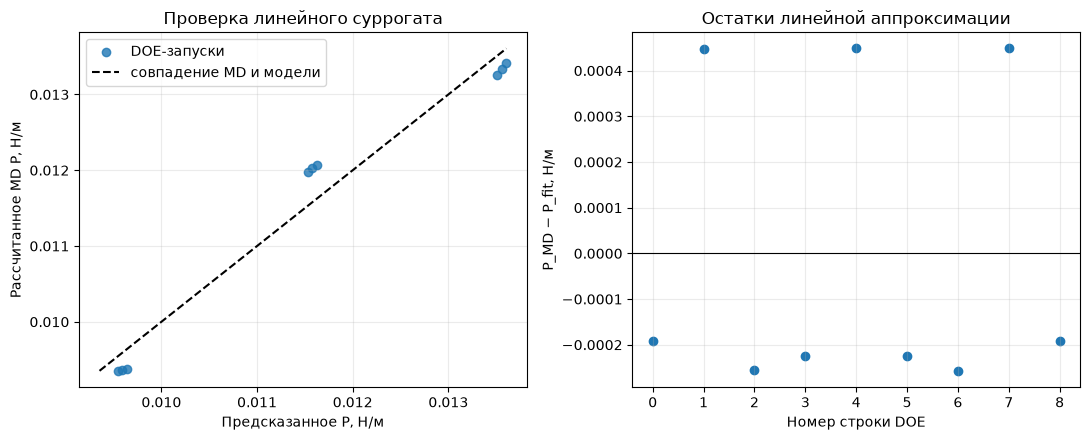

In [3]:
coefficients = fit_linear_surrogate(results)
a = coefficients['a']
dP_dT = coefficients['b_dP_dT']
dP_dN = coefficients['c_dP_dN']
pressure_observed = np.asarray([row['P_eq'] for row in results])
pressure_predicted = np.asarray(coefficients['predicted'])
print(f'P(T,N) = a + bT + cN, a = {a:.5e} Н/м')
print(f'dP/dT = b = {dP_dT:.5e} Н/(м·K)')
print(f'dP/dN = c = {dP_dN:.5e} Н/м на частицу')
print(f'R² = {coefficients["r_squared"]:.5f}; RMSE = {coefficients["rmse"]:.5e} Н/м; максимальный остаток = {coefficients["max_abs_residual"]:.5e} Н/м')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(pressure_predicted, pressure_observed, alpha=0.8, label='DOE-запуски')
low = min(np.min(pressure_predicted), np.min(pressure_observed)); high = max(np.max(pressure_predicted), np.max(pressure_observed))
axes[0].plot([low, high], [low, high], 'k--', label='совпадение MD и модели')
axes[0].set(title='Проверка линейного суррогата', xlabel='Предсказанное P, Н/м', ylabel='Рассчитанное MD P, Н/м'); axes[0].legend()
residuals = pressure_observed - pressure_predicted
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].scatter(np.arange(len(residuals)), residuals)
axes[1].set(title='Остатки линейной аппроксимации', xlabel='Номер строки DOE', ylabel='P_MD − P_fit, Н/м')
for axis in axes: axis.grid(alpha=0.25)
fig.tight_layout(); plt.show()


### Аналитический идеальный газ и чувствительность

При фиксированной площади двумерного слоя $P_{ideal}=Nk_BT/A$. Его производные находятся аналитически: $Nk_B/A$ по температуре и $k_BT/A$ по числу частиц. Единицы — соответственно Н/(м·K) и Н/м на единицу N. Сравнение помогает понять не только значения давления, но и вклад взаимодействий/стенок. Поскольку модельная observable — механическое давление x-стенки, а идеальная формула предполагает однородную равновесную систему, различия ожидаемы и не означают автоматически ошибку программы.

In [4]:
area = base_config.box.area
ideal_pressure_2d = N0 * BOLTZMANN * T0 / area
ideal_pressure_3d = ideal_pressure_2d / LAYER_THICKNESS
ideal_dP_dT = N0 * BOLTZMANN / area
ideal_dP_dN = BOLTZMANN * T0 / area
nominal_pressures = [row['P_eq'] for row in results if row['T'] == T0 and row['N'] == N0]
md_nominal_pressure = float(np.mean(nominal_pressures))

comparison = [
    ('Номинальное P_MD', md_nominal_pressure, 'Н/м'),
    ('Идеальное 2D P', ideal_pressure_2d, 'Н/м'),
    ('Идеальное эквивалентное 3D P', ideal_pressure_3d, 'Па'),
    ('Суррогат dP/dT', dP_dT, 'Н/(м·K)'),
    ('Идеальный dP/dT', ideal_dP_dT, 'Н/(м·K)'),
    ('Суррогат dP/dN', dP_dN, 'Н/м на частицу'),
    ('Идеальный dP/dN', ideal_dP_dN, 'Н/м на частицу'),
]
table = ['| Показатель | Значение | Единица |', '|---|---:|---|']
for name, value, unit in comparison: table.append(f'| {name} | {value:.6e} | {unit} |')
display(Markdown('\n'.join(table)))
print(f'Разница номинального MD давления от идеального 2D: {abs(md_nominal_pressure - ideal_pressure_2d):.5e} Н/м')
print(f'При пересчёте на моль: 1 Дж/частицу × N_A = Дж/моль; при пересчёте слоевого P₂D в Па дополнительно делим на z={LAYER_THICKNESS * 1e9:.3f} нм.')


| Показатель | Значение | Единица |
|---|---:|---|
| Номинальное P_MD | 1.202406e-02 | Н/м |
| Идеальное 2D P | 2.910413e-02 | Н/м |
| Идеальное эквивалентное 3D P | 3.901441e+07 | Па |
| Суррогат dP/dT | 4.074618e-07 | Н/(м·K) |
| Идеальный dP/dT | 2.480854e-05 | Н/(м·K) |
| Суррогат dP/dN | 3.814789e-05 | Н/м на частицу |
| Идеальный dP/dN | 2.811994e-05 | Н/м на частицу |

Разница номинального MD давления от идеального 2D: 1.70801e-02 Н/м
При пересчёте на моль: 1 Дж/частицу × N_A = Дж/моль; при пересчёте слоевого P₂D в Па дополнительно делим на z=0.746 нм.


## 5. Перенос неопределённости методом Monte Carlo

`propagate_uniform_uncertainty` создаёт воспроизводимый генератор `np.random.default_rng(seed)` и 100 000 независимых пар $(T,N)$ из равномерных диапазонов задания. Для каждой пары функция вычисляет давление линейного суррогата и возвращает массив samples, среднее, стандартное отклонение и 2.5/97.5 процентили. Это выборочное распространение **входной** неопределённости через суррогат. Оно не включает ошибку подгонки, автокорреляцию MD и межseed вариацию, если не моделировать их отдельно. Из-за линейного суррогата continuous N — математическое приближение, хотя физические расчёты DOE используют целые N. Фиксированный Monte Carlo seed обеспечивает повторяемость самого семплирования.

Среднее P по Monte Carlo: 1.15768e-02 Н/м
SD P только из заданных входных диапазонов: 1.13896e-03 Н/м
95%-й центральный интервал суррогата: [9.70513e-03, 1.34494e-02] Н/м
Линейная оценка SD при независимых равномерных T,N: 1.14011e-03 Н/м


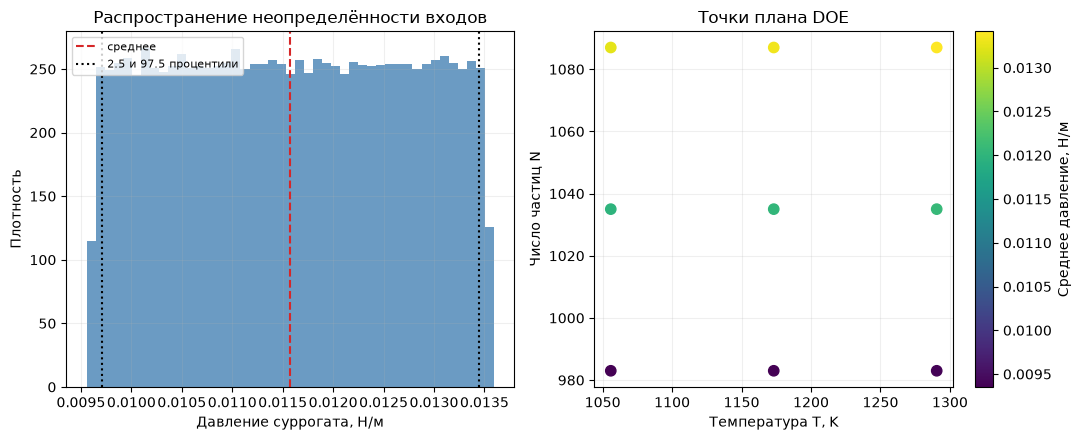

In [5]:
uncertainty = propagate_uniform_uncertainty(coefficients, T0, N0, samples=100_000, seed=2027)
temperature_std_input = (0.2 * T0) / np.sqrt(12)  # SD равномерной величины ширины 0.2*T0
particle_std_input = (0.1 * N0) / np.sqrt(12)
linearized_pressure_std = np.sqrt((dP_dT * temperature_std_input)**2 + (dP_dN * particle_std_input)**2)
print(f'Среднее P по Monte Carlo: {uncertainty["P_mean"]:.5e} Н/м')
print(f'SD P только из заданных входных диапазонов: {uncertainty["P_std"]:.5e} Н/м')
print(f'95%-й центральный интервал суррогата: [{uncertainty["P_q025"]:.5e}, {uncertainty["P_q975"]:.5e}] Н/м')
print(f'Линейная оценка SD при независимых равномерных T,N: {linearized_pressure_std:.5e} Н/м')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(uncertainty['samples'], bins=45, density=True, color='steelblue', alpha=0.8)
axes[0].axvline(uncertainty['P_mean'], color='tab:red', linestyle='--', label='среднее')
axes[0].axvline(uncertainty['P_q025'], color='black', linestyle=':', label='2.5 и 97.5 процентили')
axes[0].axvline(uncertainty['P_q975'], color='black', linestyle=':')
axes[0].set(title='Распространение неопределённости входов', xlabel='Давление суррогата, Н/м', ylabel='Плотность'); axes[0].legend(fontsize=8)
scatter = axes[1].scatter([row['T'] for row in results], [row['N'] for row in results], c=[row['P_eq'] for row in results], cmap='viridis', s=55)
axes[1].set(title='Точки плана DOE', xlabel='Температура T, K', ylabel='Число частиц N')
fig.colorbar(scatter, ax=axes[1], label='Среднее давление, Н/м')
for axis in axes: axis.grid(alpha=0.2)
fig.tight_layout(); plt.show()


### Вывод об неопределённости и границы вывода

Ширина гистограммы определяется чувствительностью суррогата и заданными диапазонами T/N. При независимых равномерных входах линеаризованная дисперсия равна $\sigma_P^2\approx b^2\sigma_T^2+c^2\sigma_N^2$; близость её к Monte Carlo SD проверяет внутреннюю согласованность линейного суррогата. Она не является полной неопределённостью физического предсказания. Для её расширения потребовались бы остаточная/параметрическая неопределённость суррогата, статистическая неопределённость MD и модельная ошибка.

Давление не обязано совпадать с идеальным газом: взаимодействия меняют вириальный/стеночный вклад, возможна неоднородность возле стенок, а симуляция конечна и статистически ограничена. Линейность проверяется остатками и областью DOE; за диапазон ±10% T и ±5% N не следует экстраполировать. При фиксированной площади N изменяет поверхностную плотность.

In [6]:
output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task5_uq'
output_dir.mkdir(parents=True, exist_ok=True)
column_names = list(results[0])
np.savetxt(output_dir / 'doe_results.csv', np.asarray([[row[name] for name in column_names] for row in results]), delimiter=',', header=','.join(column_names), comments='')
nominal_difference = abs(md_nominal_pressure - ideal_pressure_2d)
nominal_relative_percent = 100 * nominal_difference / abs(ideal_pressure_2d)
display(Markdown(f'**Вывод ({MODE}):** рассчитано {len(results)} запусков DOE при T = {TEMPERATURES.min():.1f}…{TEMPERATURES.max():.1f} K и N = {min(PARTICLE_COUNTS)}…{max(PARTICLE_COUNTS)} в фиксированной площади {area * 1e18:.1f} нм². Локальная оценка чувствительности: $dP/dT={dP_dT:.4e}$ Н/(м·K), $dP/dN={dP_dN:.4e}$ Н/м на частицу. Линейная модель: $R^2={coefficients["r_squared"]:.4f}$, RMSE={coefficients["rmse"]:.3e} Н/м. По входным диапазонам получено среднее $P={uncertainty["P_mean"]:.4e}$ Н/м, SD={uncertainty["P_std"]:.3e} Н/м, центральный 95%-й интервал [{uncertainty["P_q025"]:.4e}, {uncertainty["P_q975"]:.4e}] Н/м. Номинальное MD давление отличается от идеального 2D ориентира на {nominal_relative_percent:.2f}%. Значения относятся к {MODE}; DEMO не является окончательной статистической оценкой.'))
print(f'Результаты DOE сохранены в {output_dir.relative_to(PROJECT_ROOT) / "doe_results.csv"}')


**Вывод (DEMO):** рассчитано 9 запусков DOE при T = 1055.8…1290.5 K и N = 983…1087 в фиксированной площади 576.0 нм². Локальная оценка чувствительности: $dP/dT=4.0746e-07$ Н/(м·K), $dP/dN=3.8148e-05$ Н/м на частицу. Линейная модель: $R^2=0.9630$, RMSE=3.176e-04 Н/м. По входным диапазонам получено среднее $P=1.1577e-02$ Н/м, SD=1.139e-03 Н/м, центральный 95%-й интервал [9.7051e-03, 1.3449e-02] Н/м. Номинальное MD давление отличается от идеального 2D ориентира на 58.69%. Значения относятся к DEMO; DEMO не является окончательной статистической оценкой.

Результаты DOE сохранены в output/notebooks/task5_uq/doe_results.csv


## Возможные вопросы преподавателя

1. **Что такое чувствительность?** Наклон выхода по входу при фиксированных остальных параметрах: здесь $dP/dT$ и $dP/dN$.
2. **Чем чувствительность отличается от неопределённости?** Чувствительность — производная; неопределённость — распределение возможных выходов из-за диапазонов входов и других источников ошибки.
3. **Что такое DOE?** Заранее заданная сетка комбинаций параметров, позволяющая систематически изучить выход и оценить приближение.
4. **Зачем несколько seed?** Чтобы увидеть variation от разных начальных координат и скоростей, а не полагаться на один случайный старт.
5. **Что делает `run_simulation`?** Для одной пары T,N использует MD-движок, готовит систему рескейлингом скорости и усредняет wall pressure на production-участке.
6. **Что означает коэффициент $b$?** Приближённое изменение давления на один кельвин при фиксированном числе частиц; единицы Н/(м·K).
7. **Что означает $c$?** Локальное изменение давления при добавлении одной частицы в фиксированную площадь; вместе с N меняется плотность.
8. **Почему линейный surrogate не универсален?** Он подогнан на конечной сетке и может плохо описывать нелинейность за её пределами; проверяйте остатки и $R^2$.
9. **Что показывает Monte Carlo histogram?** Распределение давления суррогата при заданных равномерных диапазонах независимых входов, не полную ошибку модели.
10. **Почему MD отличается от идеального газа?** В MD есть межчастичные силы и стеночное взаимодействие; плюс конечная система и статистическая ошибка.